# Pipeline economía digital, **sin base de datos**

Hace lo mismo que `pipeline.ipynb` (bronze → silver → gold → análisis → figuras), pero **no se
conecta a ninguna base de datos** y **no escribe ningún archivo**: todo vive dentro de esta
notebook. Cada capa es un diccionario en memoria:

| Capa | Variable | Qué tiene |
| --- | --- | --- |
| bronze | `BRONZE` | los archivos tal como los da INEGI y OECD (ZIP y CSV, en bytes) |
| silver | `SILVER` | tablas limpias (DataFrames) |
| gold | `GOLD` | modelo estrella, estimaciones y resultados (DataFrames) |

Cada paso lee **solo** de la capa anterior. Las figuras se ven aquí abajo, en la sección 5.

En cada decisión hay un **¿Por qué?** explicado lo más simple posible.

In [1]:
import io
import re
import unicodedata
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from scipy import stats

BRONZE, SILVER, GOLD = {}, {}, {}

NACIONAL, TABASCO, YUCATAN = "00", "27", "31"
FOCO = [NACIONAL, TABASCO, YUCATAN]
N_ENTIDADES = 32
ANIOS = range(2020, 2025)


def exigir(condicion, mensaje):
    if not condicion:
        raise ValueError(mensaje)


def normalizar(texto):
    # '  ¿Disponen de Conexión?  ' -> '¿disponen de conexion?'
    sin_acentos = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode("ascii")
    return re.sub(r"\s+", " ", sin_acentos).strip().lower()


def snake(nombre):
    # 'Bien jurídico afectado' -> 'bien_juridico_afectado'
    return re.sub(r"[^a-z0-9]+", "_", normalizar(nombre)).strip("_")


def guardar(df, capa, nombre):
    capa[nombre] = df.reset_index(drop=True)
    print(f"OK   {nombre}: {len(df):,} filas")
    return df


def leer(capa, nombre):
    return capa[nombre].copy()

**¿Por qué todo en memoria?** Porque así todo queda en un solo archivo: no hay base de datos ni
carpetas que cuidar. Los datos caben de sobra en la compu.

**¿Por qué `leer` hace una copia?** Para que si un paso cambia una tabla, no se la eche a perder al
siguiente paso por accidente.

**¿Por qué las claves son texto?** Porque Yucatán es `31`, pero Campeche es `04`. Si fuera número,
el `04` se volvería `4` y ya no se podría unir con las demás tablas.

## 1. Bronze: bajar los archivos

Bronze es "lo que nos dieron, sin tocar". Se guarda cada archivo tal como llega.

In [2]:
INEGI = "https://www.inegi.org.mx/contenidos/programas"
URLS_ENDUTIH = {
    2020: f"{INEGI}/dutih/2020/datosabiertos/conjunto_de_datos_endutih_2020_csv.zip",
    2021: f"{INEGI}/dutih/2021/datosabiertos/conjunto_de_datos_endutih_2021_csv.zip",
    2022: f"{INEGI}/dutih/2022/datosabiertos/conjunto_de_datos_endutih_2022_csv.zip",
    2023: f"{INEGI}/endutih/2023/datosabiertos/conjunto_de_datos_endutih_2023_csv.zip",
    2024: f"{INEGI}/endutih/2024/datosabiertos/conjunto_de_datos_endutih_2024_csv.zip",
}
URL_VABCOEL = f"{INEGI}/vabcoel/2018/datosabiertos/conjunto_de_datos_vabcoel2018_csv.zip"
URL_PIBE = f"{INEGI}/pibent/2018/datosabiertos/pibe_datos_abiertos_csv.zip"
OECD_SDMX = "https://sdmx.oecd.org/public/rest/data/OECD.STI.DEP"
URLS_OECD = {
    "oecd_ict_hogares": f"{OECD_SDMX},DSD_ICT_HH_IND@DF_HH,/"
                        ".A.A1_HH+B1_HH+B21A_HH+B21B_HH.PT_HH._T._Z._Z._Z._T._Z?startPeriod=2015",
    "oecd_ict_individuos": f"{OECD_SDMX},DSD_ICT_HH_IND@DF_IND,/"
                           ".A.C5B_I+C2B_I+G1_I+D1T_I+D1U_I+F1_I+D1B_I.PT_POP._Z.Y16T74._T._T._T._T"
                           "?startPeriod=2015",
}
HEADERS_OECD = {"Accept": "application/vnd.sdmx.data+csv; charset=utf-8; labels=both"}


def bajar(url, archivo, **kwargs):
    if archivo in BRONZE:
        print(f"ya estaba  {archivo}")
        return
    r = requests.get(url, timeout=600, **kwargs)
    r.raise_for_status()
    # INEGI contesta 200 con una página HTML cuando el archivo no existe
    exigir(not archivo.endswith(".zip") or r.content.startswith(b"PK"), f"{url} no es un ZIP (¿cambió la URL?)")
    exigir(len(r.content) > 0, f"{url} vino vacío")
    BRONZE[archivo] = r.content
    print(f"OK   {archivo}: {len(r.content) / 1e6:.1f} MB")


for anio, url in URLS_ENDUTIH.items():
    bajar(url, f"endutih_{anio}.zip")
bajar(URL_VABCOEL, "vabcoel.zip")
bajar(URL_PIBE, "pibe.zip")
for nombre, url in URLS_OECD.items():
    bajar(url, f"{nombre}.csv", headers=HEADERS_OECD)

OK   endutih_2020.zip: 8.5 MB


OK   endutih_2021.zip: 8.5 MB


OK   endutih_2022.zip: 8.5 MB


OK   endutih_2023.zip: 10.5 MB


OK   endutih_2024.zip: 8.7 MB


OK   vabcoel.zip: 0.0 MB


OK   pibe.zip: 4.7 MB


OK   oecd_ict_hogares.csv: 0.4 MB


OK   oecd_ict_individuos.csv: 0.9 MB


- **¿Por qué guardar los ZIP enteros?** Porque así bronze es una copia exacta de lo que dio INEGI.
  Si después nos equivocamos limpiando, podemos volver a empezar sin bajar nada.
- **¿Por qué no se baja otra vez si ya está?** Porque INEGI tarda mucho. Si corres esta celda dos
  veces, la segunda ya no baja nada. Si quieres datos nuevos, reinicia el kernel.
- **¿Por qué 2020 a 2024 y no 2019?** Porque el archivo de 2019 no dice en qué estado vive cada
  familia, y sin eso no podemos comparar Yucatán con Tabasco.
- **¿Por qué OECD solo pide el total del país?** Porque el archivo completo pesa como 180 MB y solo
  usamos el número de todo el país.
- **¿Por qué se revisa que empiece con `PK`?** Porque todos los ZIP empiezan así. Si no, INEGI nos
  mandó una página de error disfrazada.

## 2. Silver: limpiar

Aquí se leen los archivos de bronze y se dejan ordenados. Cada cosa que se cambia o se tira se
anota en `log`, que al final queda en `SILVER["etl_log"]`.

In [3]:
log = []


def anotar(tabla, metrica, valor, detalle=None):
    log.append((tabla, metrica, int(valor), detalle))


def texto_csv(raw):
    # Los CSV de INEGI vienen en UTF-8 (algunos con BOM); latin-1 queda de respaldo
    try:
        return raw.decode("utf-8-sig")
    except UnicodeDecodeError:
        return raw.decode("latin-1")


def leer_csv(raw, **kwargs):
    df = pd.read_csv(io.StringIO(texto_csv(raw)), dtype=str, keep_default_na=False, na_values=[""], **kwargs)
    df.columns = [snake(c) for c in df.columns]
    return df


def si_no(serie, columna):
    # '1' -> True, '2' -> False, vacío -> NA. Cualquier otro código es error.
    s = serie.str.strip()
    invalidos = s.notna() & ~s.isin(["1", "2"])
    exigir(not invalidos.any(), f"{columna}: códigos fuera de 1/2 {s[invalidos].unique()[:10].tolist()}")
    return s.map({"1": True, "2": False}).astype("boolean")


def a_entero(serie, columna):
    s = serie.str.strip()
    exigir(s.dropna().str.fullmatch(r"[0-9]+").all(), f"{columna}: valores no numéricos")
    return s.astype("Int64")


anotar("endutih", "anio_2019_excluido", 1, "datos abiertos 2019 sin clave de entidad")

- **¿Por qué `1` = Sí y `2` = No se vuelven `True`/`False`?** Porque así se puede sumar y sacar
  porcentajes fácil. Si sale un `7` o un `9` raro, el programa se detiene, porque no sabemos qué es.
- **¿Por qué se anota todo en `log`?** Para que cualquiera vea qué se borró o se cambió, y cuántas
  filas fueron.

### 2.1 Catálogo de entidades

In [4]:
def archivo_en_zip(z, terminacion):
    return [n for n in z.namelist() if n.endswith(terminacion)]


catalogo = None
for anio in ANIOS:
    z = zipfile.ZipFile(io.BytesIO(BRONZE[f"endutih_{anio}.zip"]))
    encontrados = archivo_en_zip(z, "tc_endutih_entidad.csv")
    if encontrados:
        catalogo = leer_csv(z.read(encontrados[0]))
exigir(catalogo is not None, "ningún año trae el catálogo de entidades")

cat = pd.DataFrame({"cve_ent": catalogo["cve_ent"].str.strip().str.zfill(2), "nombre": catalogo["nom_ent"].str.strip()})
exigir(len(cat) == N_ENTIDADES and cat["cve_ent"].is_unique, "se esperaban 32 entidades únicas")
cat = pd.concat([pd.DataFrame([{"cve_ent": NACIONAL, "nombre": "Estados Unidos Mexicanos"}]), cat], ignore_index=True)
anotar("cat_entidad", "fila_nacional_agregada", 1, "cve_ent '00' = Estados Unidos Mexicanos")
cat["nombre_normalizado"] = cat["nombre"].map(normalizar)
cat["es_foco"] = cat["cve_ent"].isin(FOCO)
guardar(cat, SILVER, "cat_entidad");

OK   cat_entidad: 33 filas


- **¿Por qué se usa el catálogo del último año?** Porque es el más nuevo, y los nombres de los
  estados no cambian.
- **¿Por qué se agrega la fila `00`?** Porque México entero también es "un lugar" que queremos
  comparar. Con la clave `00` todas las tablas usan la misma llave.

### 2.2 Qué pregunta es cada cosa en cada año

In [5]:
# concepto -> (archivo, palabra que debe decir la pregunta en el diccionario, {años: [columnas]})
MAPEO_HOGAR = {
    "computadora": ("hogares", "dispon", {
        (2020, 2021): ["p4_2_1", "p4_2_2", "p4_2_3"],
        (2022, 2023, 2024): ["p4_2_1_1", "p4_2_2_1", "p4_2_3_1"],
    }),
    "internet": ("hogares", "conexion a internet en el hogar", {ANIOS: ["p4_4"]}),
    "tipo_conexion": ("hogares", "fija, movil o de ambas", {ANIOS: ["p4_5"]}),
    "celular": ("hogares", "celular", {ANIOS: ["p4_1_6"]}),
    "razon_sin_internet": ("hogares", "por que no disponen de internet", {ANIOS: ["p4_8"]}),
}
MAPEO_PERSONA = {
    "usa_internet": ("usuarios", "ha utilizado internet", {ANIOS: ["p7_1"]}),
    "usa_computadora": ("usuarios", "utilizo computadora", {ANIOS: ["p6_1"]}),
    "usa_redes_sociales": ("usuarios", "redes sociales", {(2020, 2021, 2022): ["p7_13"], (2023, 2024): ["p7_15"]}),
    "vende_internet": ("usuarios", "ventas por internet", {(2020, 2021, 2022): ["p7_17"], (2023, 2024): ["p7_19"]}),
    "compra_internet": ("usuarios", "compras por internet", {(2020, 2021, 2022): ["p7_19"], (2023, 2024): ["p7_21"]}),
    "paga_internet": ("usuarios", "pagos por internet", {(2020, 2021, 2022): ["p7_27"], (2023, 2024): ["p7_28"]}),
    "banca_electronica": ("usuarios", "banca electronica", {(2020, 2021, 2022): ["p7_32"], (2023, 2024): ["p7_33"]}),
    "usa_celular": ("usuarios2", "telefono celular", {ANIOS: ["p8_3"]}),
    "usa_smartphone": ("usuarios2", "inteligente", {ANIOS: ["p8_4_2"]}),
}
PATRON_ARCHIVO = {"hogares": r"tr_endutih_hogar(es)?_anual", "usuarios": r"tr_endutih_usuario(s)?_anual",
                  "usuarios2": r"tr_endutih_usuario(s)?2_anual"}


def columnas_del_anio(mapeo, anio):
    salida = {}
    for concepto, (tabla, clave, por_anios) in mapeo.items():
        cols = [c for anios, cs in por_anios.items() if anio in anios for c in cs]
        exigir(bool(cols), f"{concepto} no tiene columna para {anio}")
        salida[concepto] = (tabla, clave, cols)
    return salida


def archivo_endutih(z, anio, tabla):
    datos = [n for n in z.namelist() if re.search(rf"conjuntos?_de_datos/{PATRON_ARCHIVO[tabla]}_{anio}\.csv$", n)]
    exigir(len(datos) == 1, f"endutih {anio}: se esperaba 1 archivo de {tabla}, hay {datos}")
    return datos[0]


diccionarios = []
for anio in ANIOS:
    z = zipfile.ZipFile(io.BytesIO(BRONZE[f"endutih_{anio}.zip"]))
    for tabla in PATRON_ARCHIVO:
        nombre = archivo_endutih(z, anio, tabla).split("/")[-1]
        dic = [n for n in z.namelist() if "diccionario" in n.lower() and n.endswith(nombre)]
        exigir(len(dic) == 1, f"endutih {anio}: no está el diccionario de {nombre}")
        d = leer_csv(z.read(dic[0]))
        d["anio"], d["tabla"] = anio, tabla
        diccionarios.append(d)
dic = pd.concat(diccionarios, ignore_index=True)
dic["col"] = dic["columna"].fillna(dic["campo"]).str.strip().str.lower()
dic["desc_norm"] = dic["descripcion"].map(normalizar)
anotar("endutih_mapeo_variables", "diccionarios_con_campo_en_vez_de_columna", dic["columna"].isna().sum())

filas = []
for anio in ANIOS:
    for mapeo in (MAPEO_HOGAR, MAPEO_PERSONA):
        for concepto, (tabla, clave, cols) in columnas_del_anio(mapeo, anio).items():
            for col in cols:
                d = dic[(dic["anio"] == anio) & (dic["tabla"] == tabla) & (dic["col"] == col)]
                exigir(len(d) == 1, f"{anio}: {tabla}.{col} no está en el diccionario")
                exigir(clave in d["desc_norm"].iloc[0], f"{anio}: {tabla}.{col} ({concepto}) no dice '{clave}'")
                filas.append((anio, concepto, f"endutih_{tabla}_{anio}", col, d["descripcion"].iloc[0].strip()))
mapeo = pd.DataFrame(filas, columns=["anio", "concepto", "tabla_bronze", "columna", "descripcion_diccionario"])
anotar("endutih_mapeo_variables", "columnas_validadas_contra_diccionario", len(mapeo))
guardar(mapeo, SILVER, "endutih_mapeo_variables");

OK   endutih_mapeo_variables: 80 filas


- **¿Por qué una tabla de "qué pregunta es cada cosa"?** Porque INEGI cambia el número de las
  preguntas de un año a otro. "¿Compraste por internet?" es la `P7_19` en 2020 y la `P7_21` en 2023.
  Si no lo cuidamos, mezclamos peras con manzanas.
- **¿Por qué se revisa con el diccionario?** Porque así la computadora checa que la pregunta
  de verdad habla de lo que creemos (por ejemplo, que diga "compras por internet"). Si INEGI cambia
  algo, el programa se detiene en vez de dar un resultado equivocado.
- **¿Por qué `campo` o `columna`?** Porque el diccionario de 2020 le puso otro nombre a la misma
  cosa.

### 2.3 Hogares y personas de la ENDUTIH

In [6]:
ANCHO_LLAVES = {"cve_ent": 2, "upm": 7, "viv_sel": 2, "hogar": 2, "num_ren": 2, "est_dis": 3, "upm_dis": 5}


def leer_endutih(tabla, anio, columnas):
    z = zipfile.ZipFile(io.BytesIO(BRONZE[f"endutih_{anio}.zip"]))
    quiero = set(columnas) | {"ent", "cve_ent"}
    df = leer_csv(z.read(archivo_endutih(z, anio, tabla)), usecols=lambda c: snake(c) in quiero)
    # La clave de entidad se llama 'ent' hasta 2023 y 'cve_ent' en 2024
    if "cve_ent" not in df:
        df = df.rename(columns={"ent": "cve_ent"})
    df = df.drop(columns="ent", errors="ignore")
    faltan = [c for c in columnas if c not in df]
    exigir(not faltan, f"endutih_{tabla}_{anio}: faltan columnas {faltan}")
    for c, ancho in ANCHO_LLAVES.items():
        if c in df:
            cortas = df[c].str.strip().str.len() < ancho
            if cortas.any():
                anotar(f"endutih_{tabla}", f"llave_{c}_rellenada_con_ceros_{anio}", cortas.sum())
            antes = df[c].str.strip().nunique()
            df[c] = df[c].str.strip().str.zfill(ancho)
            exigir(df[c].nunique() == antes, f"endutih_{tabla}_{anio}: rellenar '{c}' con ceros junta claves distintas")
    return df


cves = set(cat["cve_ent"]) - {NACIONAL}

- **¿Por qué solo se leen algunas columnas?** Porque cada archivo trae como 230 preguntas y solo
  usamos unas 20. Leer todo llenaría la memoria de la compu.
- **¿Por qué se rellenan las claves con ceros?** Porque algunos años escriben `7` y otros `07`
  para lo mismo. Con ceros todos se ven igual y se pueden unir.
- **¿Y si rellenar junta dos claves distintas?** Se detiene, porque eso querría decir que `1` y
  `01` eran cosas distintas, y no queremos mezclarlas.
- **¿Por qué no se usan los archivos de residentes y viviendas?** Porque ningún número del proyecto
  sale de ahí.

In [7]:
partes = []
for anio in ANIOS:
    cols = columnas_del_anio(MAPEO_HOGAR, anio)
    fuente_cols = [c for _, _, cs in cols.values() for c in cs]
    df = leer_endutih("hogares", anio, ["upm", "viv_sel", "hogar", "est_dis", "upm_dis", "tloc", "fac_hog", *fuente_cols])
    anotar("endutih_hogar", f"registros_bronze_{anio}", len(df))

    sal = df[["upm", "viv_sel", "hogar", "cve_ent", "est_dis", "upm_dis"]].copy()
    sal["anio"] = anio
    sal["tloc"] = a_entero(df["tloc"], "tloc")
    sal["fac_hog"] = a_entero(df["fac_hog"], "fac_hog")

    compu = pd.concat([si_no(df[c], c) for c in cols["computadora"][2]], axis=1)
    exigir(compu.notna().all().all(), f"hogar {anio}: computadora con vacíos")
    sal["tiene_computadora"] = compu.any(axis=1).astype(bool)

    for concepto, destino in [("internet", "tiene_internet"), ("celular", "tiene_celular")]:
        col = cols[concepto][2][0]
        v = si_no(df[col], col)
        exigir(v.notna().all(), f"hogar {anio}: {col} con vacíos")
        sal[destino] = v.astype(bool)

    # P4_5: 1 solo fija, 2 solo móvil, 3 ambas, 9 no sabe; vacío si el hogar no tiene internet
    tipo = df[cols["tipo_conexion"][2][0]].str.strip()
    exigir((tipo.isna() == ~sal["tiene_internet"]).all(), f"hogar {anio}: P4_5 no respeta el salto de P4_4")
    exigir(tipo.dropna().isin(["1", "2", "3", "9"]).all(), f"hogar {anio}: P4_5 con códigos desconocidos")
    sal["internet_fija"] = tipo.map({"1": True, "3": True, "2": False, "9": pd.NA}).astype("boolean")
    sal.loc[~sal["tiene_internet"], "internet_fija"] = False
    anotar("endutih_hogar", f"tipo_conexion_no_sabe_a_null_{anio}", (tipo == "9").sum())

    razon = a_entero(df[cols["razon_sin_internet"][2][0]], "p4_8")
    exigir((razon.notna() == ~sal["tiene_internet"]).all(), f"hogar {anio}: P4_8 no respeta el salto de P4_4")
    sal["razon_sin_internet"] = razon
    partes.append(sal)

hogar = pd.concat(partes, ignore_index=True)
exigir(hogar["cve_ent"].isin(cves).all(), "hogar: cve_ent fuera del catálogo")
exigir(not hogar.duplicated(["anio", "upm", "viv_sel", "hogar"]).any(), "hogar: llave duplicada")
exigir((hogar["fac_hog"] > 0).all(), "hogar: factor de expansión no positivo")
exigir(hogar.groupby("anio")["cve_ent"].nunique().eq(N_ENTIDADES).all(), "hogar: algún año no tiene las 32 entidades")
guardar(hogar, SILVER, "endutih_hogar");

OK   endutih_hogar: 292,981 filas


- **¿Por qué "tiene computadora" junta escritorio, laptop y tablet?** Porque así lo cuenta INEGI y
  también la OECD. Si tienes cualquiera de las tres, cuentas.
- **¿Por qué "no sabe" (9) en tipo de conexión se deja vacío?** Porque no sabemos la respuesta, y
  es mejor no adivinar. Esos hogares no se cuentan en ese porcentaje.
- **¿Por qué un hogar sin internet tiene `internet_fija = False`?** Porque si no tienes internet,
  seguro tampoco tienes internet fijo.
- **¿Por qué se revisa el "salto"?** Porque la encuesta solo pregunta "¿por qué no tienes internet?"
  a quien no tiene. Si alguien con internet contestó eso, algo está mal y mejor nos detenemos.
- **¿Por qué el factor de expansión debe ser mayor que 0?** Porque dice a cuántos hogares de verdad
  representa cada hogar de la encuesta. Representar a 0 o a -5 hogares no tiene sentido.

In [8]:
LLAVES = ["upm", "viv_sel", "hogar", "num_ren"]
SOLO_USUARIOS_INTERNET = ["usa_redes_sociales", "vende_internet", "compra_internet", "paga_internet", "banca_electronica"]

partes = []
for anio in ANIOS:
    cols = columnas_del_anio(MAPEO_PERSONA, anio)
    de = lambda t: [c for tb, _, cs in cols.values() if tb == t for c in cs]
    u = leer_endutih("usuarios", anio, [*LLAVES, "est_dis", "upm_dis", "tloc", "fac_per", "edad", "sexo", *de("usuarios")])
    u2 = leer_endutih("usuarios2", anio, [*LLAVES, *de("usuarios2")]).drop(columns="cve_ent")
    anotar("endutih_persona", f"registros_bronze_{anio}", len(u))

    df = u.merge(u2, on=LLAVES, how="outer", indicator=True, validate="one_to_one")
    exigir((df["_merge"] == "both").all(), f"persona {anio}: usuarios y usuarios2 no traen las mismas personas")

    sal = df[[*LLAVES, "cve_ent", "est_dis", "upm_dis"]].copy()
    sal["anio"] = anio
    for c in ["tloc", "fac_per", "edad", "sexo"]:
        sal[c] = a_entero(df[c], c)

    for concepto in ["usa_internet", "usa_computadora", "usa_celular"]:
        col = cols[concepto][2][0]
        v = si_no(df[col], col)
        exigir(v.notna().all(), f"persona {anio}: {col} ({concepto}) con vacíos")
        sal[concepto] = v.astype(bool)

    for concepto in SOLO_USUARIOS_INTERNET:
        col = cols[concepto][2][0]
        v = si_no(df[col], col)
        exigir(v[sal["usa_internet"]].notna().all(), f"persona {anio}: {col} vacío entre usuarios de internet")
        exigir(v[~sal["usa_internet"]].isna().all(), f"persona {anio}: {col} contestado por quien no usa internet")
        sal[concepto] = v.fillna(False).astype(bool)
    anotar("endutih_persona", f"no_usuarios_internet_salto_a_false_{anio}", (~sal["usa_internet"]).sum())

    col = cols["usa_smartphone"][2][0]
    v = si_no(df[col], col)
    exigir(v[sal["usa_celular"]].notna().all(), f"persona {anio}: {col} vacío entre usuarios de celular")
    sal["usa_smartphone"] = v.fillna(False).astype(bool)
    partes.append(sal)

persona = pd.concat(partes, ignore_index=True)
exigir(persona["cve_ent"].isin(cves).all(), "persona: cve_ent fuera del catálogo")
exigir(not persona.duplicated(["anio", *LLAVES]).any(), "persona: llave duplicada")
exigir((persona["edad"] >= 6).all(), "persona: hay menores de 6 años")
exigir((persona["fac_per"] > 0).all(), "persona: factor de expansión no positivo")
guardar(persona, SILVER, "endutih_persona");

OK   endutih_persona: 292,981 filas


- **¿Por qué se juntan `usuarios` y `usuarios2`?** Porque son la misma persona, solo que INEGI
  partió sus respuestas en dos archivos. Se revisa que estén exactamente las mismas personas.
- **¿Por qué si no usas internet tu "compra por internet" es `False`?** Porque a quien no usa
  internet ni le preguntan. Si no usas internet, no compraste por internet.
- **¿Y si alguien que sí usa internet no contestó?** Se detiene, porque eso sí es un dato que falta
  de verdad y no lo queremos inventar.
- **¿Por qué solo mayores de 6 años?** Porque la encuesta solo pregunta a personas de 6 años o más.

### 2.4 Comercio electrónico (VABCOEL), PIB por estado y OECD

In [9]:
ESTATUS_CIFRA = {"r": "revisada", "p": "preliminar"}


def tabulado_a_largo(df, id_vars):
    # Una columna por año ('2023_r', '2024_p') -> una fila por año
    anios = {c: m for c in df.columns if (m := re.fullmatch(r"(\d{4})(?:_([rp]))?", c))}
    largo = df.melt(id_vars=id_vars, value_vars=list(anios), var_name="col_anio", value_name="valor_txt")
    largo["anio"] = largo["col_anio"].map(lambda c: int(anios[c].group(1)))
    largo["estatus_cifra"] = largo["col_anio"].map(lambda c: ESTATUS_CIFRA.get(anios[c].group(2), "definitiva"))
    largo["valor"] = pd.to_numeric(largo["valor_txt"].replace({"NA": None}), errors="raise")
    return largo


# ---- VABCOEL
MEDIDAS_VABCOEL = {
    ("coel_corr", "millones de pesos a precios corrientes"): "mdp_corrientes",
    ("coel_cte", "millones de pesos a precios de 2018"): "mdp_constantes_2018",
    ("pcoel_pibt", "participacion porcentual"): "pct_pib",
    ("pcoel_vabt", "participacion porcentual"): "pct_vab",
    ("pcoel_aeta", "participacion porcentual"): "pct_vab_actividad",
}
COMPONENTES_VABCOEL = {"total": "total", "comercio al por mayor": "comercio_al_por_mayor",
                       "comercio al por menor": "comercio_al_por_menor", "otros servicios": "otros_servicios"}

z = zipfile.ZipFile(io.BytesIO(BRONZE["vabcoel.zip"]))
indice = pd.read_csv(io.StringIO(texto_csv(z.read("conjunto_de_datos/indice.csv"))), header=None,
                     names=["archivo", "titulo"], dtype=str)
df = pd.concat([leer_csv(z.read(f"conjunto_de_datos/{a}")).assign(archivo=a) for a in indice["archivo"]],
               ignore_index=True)
anotar("vabcoel", "renglones_bronze", len(df))
partes = df["descriptores"].str.replace(r"<[^>]+>", "", regex=True).str.split("|")
df["unidad"] = partes.str[0].map(normalizar)
df["clave_archivo"] = df["archivo"].str.extract(r"conjunto_de_datos_([a-z]+_[a-z]+)_")[0]
df["medida"] = [MEDIDAS_VABCOEL.get((a, u)) for a, u in zip(df["clave_archivo"], df["unidad"])]
descartados = df["medida"].isna()
anotar("vabcoel", "renglones_derivados_descartados", descartados.sum())
df = df[~descartados].copy()
ultimo = partes[~descartados].str[-1].map(normalizar)
df["componente"] = ultimo.map(COMPONENTES_VABCOEL).fillna(ultimo.map(lambda u: "total" if u == "valor agregado bruto" else None))
exigir(df["componente"].notna().all(), "vabcoel: componentes desconocidos")
vabcoel = tabulado_a_largo(df, ["medida", "componente"])
exigir(vabcoel["valor"].notna().all(), "vabcoel: niveles con 'NA'")
exigir(not vabcoel.duplicated(["anio", "componente", "medida"]).any(), "vabcoel: llave duplicada")
corr = vabcoel[vabcoel["medida"] == "mdp_corrientes"].pivot(index="anio", columns="componente", values="valor")
suma = corr[["comercio_al_por_mayor", "comercio_al_por_menor", "otros_servicios"]].sum(axis=1)
exigir(((suma / corr["total"] - 1).abs() < 0.001).all(), "vabcoel: las partes no suman el total")
guardar(vabcoel[["anio", "componente", "medida", "valor", "estatus_cifra"]], SILVER, "vabcoel");

OK   vabcoel: 228 filas


- **¿Por qué se tiran los renglones de "variación" y "estructura"?** Porque se pueden calcular con
  los números de base. Guardarlos dos veces solo trae números con redondeos distintos.
- **¿Por qué "Otros servicios" no es parte de "comercio al por menor"?** Porque INEGI lo dibujó
  colgando de ahí, pero su propia nota dice que es otra cosa. Le hacemos caso a la nota.
- **¿Por qué se revisa que las partes sumen el total?** Porque si mayoreo + menudeo + otros no da
  el total, algo se leyó mal.

In [10]:
PRECIOS_PIBE = {"millones de pesos": "corrientes", "millones de pesos a precios de 2018": "constantes_2018"}
CONCEPTOS_PIBE = {
    "conjunto_de_datos_pibe_actividad_b.1bv2023_p.csv": "vab_total",
    "conjunto_de_datos_pibe_actividad_512023_p.csv": "vab_51",
    "conjunto_de_datos_pibe_actividad_212023_p.csv": "vab_21",
}
z = zipfile.ZipFile(io.BytesIO(BRONZE["pibe.zip"]))
df = pd.concat([leer_csv(z.read(f"conjunto_de_datos/{a}")).assign(archivo=a) for a in CONCEPTOS_PIBE], ignore_index=True)
anotar("pib_entidad", "renglones_bronze", len(df))
partes = df["descriptores"].str.replace(r"<[^>]+>", "", regex=True).str.split("|")
df["precios"] = partes.str[0].map(normalizar).map(PRECIOS_PIBE)
df["concepto"] = df["archivo"].map(CONCEPTOS_PIBE)
exigir(partes.str[1].str.startswith("B.1bV").all(), "pib: se esperaba solo valor agregado bruto")
descartados = df["precios"].isna()
anotar("pib_entidad", "renglones_derivados_descartados", descartados.sum())
df = df[~descartados].copy()
nombre = partes[~descartados].str[2].map(normalizar)
df["cve_ent"] = nombre.map(cat.set_index("nombre_normalizado")["cve_ent"])
exigir(df["cve_ent"].notna().all(), f"pib: estados sin clave {nombre[df['cve_ent'].isna()].unique()}")
exigir(df["cve_ent"].nunique() == N_ENTIDADES + 1, "pib: no están las 32 entidades más el nacional")
pib = tabulado_a_largo(df, ["cve_ent", "concepto", "precios"]).rename(columns={"valor": "valor_mdp"})
exigir(pib["valor_mdp"].notna().all(), "pib: niveles con 'NA'")
t = pib[pib["concepto"] == "vab_total"]
est = t[t["cve_ent"] != NACIONAL].groupby(["anio", "precios"])["valor_mdp"].sum()
nac = t[t["cve_ent"] == NACIONAL].set_index(["anio", "precios"])["valor_mdp"]
exigir(((est / nac - 1).abs() < 0.001).all(), "pib: la suma de los estados no da el nacional")
guardar(pib[["anio", "cve_ent", "concepto", "precios", "valor_mdp", "estatus_cifra"]], SILVER, "pib_entidad");

OK   pib_entidad: 4,158 filas


- **¿Por qué solo 3 de los 79 archivos del PIB?** Porque solo usamos el total, el sector 51
  (información: internet, telecom, software) y el 21 (minería).
- **¿Por qué la minería?** Porque Tabasco tiene mucho petróleo. Si no lo quitamos, parece que
  Tabasco casi no tiene sector de información, cuando en realidad el petróleo lo tapa todo.
- **¿Por qué se une por nombre del estado?** Porque el archivo del PIB no trae la clave, solo el
  nombre. Se quitan acentos y mayúsculas, y si algún nombre no encaja, se detiene.
- **¿Por qué se revisa que los estados sumen el nacional?** Porque 32 pedacitos deben dar el pastel
  completo. Si no, algo se leyó mal.

In [11]:
UNIDADES_OECD = {"PT_HH": "pct_hogares", "PT_POP": "pct_personas_16_74"}
partes = []
for tabla in URLS_OECD:
    df = pd.read_csv(io.BytesIO(BRONZE[f"{tabla}.csv"]), dtype=str)
    df.columns = [snake(c.split(":")[0]) for c in df.columns]  # 'REF_AREA: Reference area' -> 'ref_area'
    anotar("oecd_ict", f"registros_bronze_{tabla}", len(df))
    partes.append(df)
df = pd.concat(partes, ignore_index=True)
df[["cod_pais", "pais"]] = df["ref_area"].str.split(": ", n=1, expand=True)
df[["medida", "desc_medida"]] = df["measure"].str.split(": ", n=1, expand=True)
df["unidad"] = df["unit_measure"].str.split(":").str[0].map(UNIDADES_OECD)
exigir(df["unidad"].notna().all(), "oecd: unidad desconocida")
df["anio"] = df["time_period"].astype(int)
df["valor"] = pd.to_numeric(df["obs_value"], errors="coerce")
sin_valor = df["valor"].isna()
anotar("oecd_ict", "observaciones_sin_valor_descartadas", sin_valor.sum())
oecd = df[~sin_valor].copy()
oecd["estatus_obs"] = oecd["obs_status"].str.split(": ", n=1).str[1]
exigir(not oecd.duplicated(["anio", "cod_pais", "medida"]).any(), "oecd: llave duplicada")
guardar(oecd[["anio", "cod_pais", "pais", "medida", "desc_medida", "unidad", "valor", "estatus_obs"]], SILVER, "oecd_ict")

guardar(pd.DataFrame(log, columns=["tabla", "metrica", "valor", "detalle"]), SILVER, "etl_log");

OK   oecd_ict: 3,656 filas
OK   etl_log: 57 filas


- **¿Por qué se tiran los datos de OECD sin número?** Porque un dato vacío no sirve para comparar.
- **¿Por qué se guarda la "bandera" de OECD?** Porque a veces OECD avisa "ojo, este número se midió
  distinto". No lo borramos, pero lo dejamos marcado.

## 3. Gold: el modelo estrella y las estimaciones

Gold lee **solo** las tablas de silver.

In [12]:
cat = leer(SILVER, "cat_entidad")
hogar = leer(SILVER, "endutih_hogar")
persona = leer(SILVER, "endutih_persona")
vabcoel = leer(SILVER, "vabcoel")
pib = leer(SILVER, "pib_entidad")
oecd = leer(SILVER, "oecd_ict")

dim_entidad = cat[["cve_ent", "nombre", "es_foco"]].copy()
dim_entidad.loc[dim_entidad["cve_ent"] == NACIONAL, "nombre"] = "México (nacional)"
exigir(len(dim_entidad) == N_ENTIDADES + 1, "dim_entidad: se esperaban 33 filas")

anios = pd.concat([vabcoel["anio"], pib["anio"], hogar["anio"], oecd["anio"]])
dim_tiempo = pd.DataFrame({"anio": range(anios.min(), anios.max() + 1)})
dim_tiempo["sexenio"] = pd.cut(dim_tiempo["anio"], [0, 2006, 2012, 2018, 2024, 9999],
                               labels=["2000-2006", "2006-2012", "2012-2018", "2018-2024", "2024-2030"]).astype(str)

dim_pais = oecd.sort_values("anio").groupby("cod_pais", as_index=False)["pais"].last().rename(columns={"pais": "nombre"})

guardar(dim_entidad, GOLD, "dim_entidad")
guardar(dim_tiempo, GOLD, "dim_tiempo")
guardar(dim_pais, GOLD, "dim_pais")
guardar(pib, GOLD, "fact_valor_entidad")
guardar(vabcoel, GOLD, "fact_comercio_electronico")
guardar(oecd.drop(columns="pais"), GOLD, "fact_oecd_tic");

OK   dim_entidad: 33 filas
OK   dim_tiempo: 23 filas
OK   dim_pais: 45 filas
OK   fact_valor_entidad: 4,158 filas
OK   fact_comercio_electronico: 228 filas
OK   fact_oecd_tic: 3,656 filas


- **¿Por qué un "modelo estrella"?** Porque es como un dibujo de una estrella: en el centro los
  números (hechos) y alrededor las cosas que los describen (estado, año, indicador, país). Así es
  fácil filtrar y cruzar.
- **¿Por qué el sexenio en la tabla de años?** Para poder agrupar por gobierno si alguien quiere.
- **¿Por qué el nombre más nuevo del país?** Porque si OECD cambió cómo escribe un país, nos
  quedamos con el último.

### 3.1 Estimaciones de la encuesta

La ENDUTIH no pregunta a todo México, pregunta a una **muestra**. Cada hogar o persona de la
encuesta "vale" por muchos (su factor de expansión `fac_hog` o `fac_per`).

- El porcentaje se calcula como: (suma de los factores de quienes dicen "sí") / (suma de los
  factores de todos).
- El **error estándar** dice qué tanto podría moverse ese número si se hubiera preguntado a otras
  casas. Se calcula con el diseño de la muestra (estratos `est_dis` y conglomerados `upm_dis`).
- El **intervalo al 90%** es "el número real casi seguro está entre estos dos".
- La **calidad** sale del coeficiente de variación (CV = error / estimación): menos de 15 es alta,
  de 15 a 30 moderada y más de 30 baja.

In [13]:
Z_90 = 1.6448536269514722

# id -> (nombre, dimensión, unidad, universo, tabla, columna, denominador, descripción)
#   denominador: None = todos; columna booleana = solo donde es True; 'sin_internet' = hogares sin internet
#   columna 'razon=k' = razon_sin_internet == k
INDICADORES = {
    "hog_internet": ("Hogares con internet", "acceso", "% de hogares", "Hogares", "hogar", "tiene_internet", None,
                     "Hogares que disponen de conexión a internet (fija o móvil). ENDUTIH P4_4."),
    "hog_computadora": ("Hogares con computadora", "acceso", "% de hogares", "Hogares", "hogar", "tiene_computadora",
                        None, "Hogares con computadora de escritorio, laptop o tablet. ENDUTIH P4_2."),
    "hog_internet_fija": ("Hogares con internet fijo", "acceso", "% de hogares", "Hogares", "hogar", "internet_fija",
                          None, "Hogares con conexión fija (sola o junto con móvil). Excluye 'no sabe'. ENDUTIH P4_5."),
    "hog_celular": ("Hogares con celular", "acceso", "% de hogares", "Hogares", "hogar", "tiene_celular", None,
                    "Hogares donde algún integrante dispone de teléfono celular. ENDUTIH P4_1_6."),
    "pob_smartphone": ("Usuarios de smartphone", "acceso", "% de la población de 6+", "Personas de 6 años y más",
                       "persona", "usa_smartphone", None,
                       "Personas que usaron un celular inteligente en los últimos 3 meses. ENDUTIH P8_3 y P8_4_2."),
    "pob_internet": ("Usuarios de internet", "uso", "% de la población de 6+", "Personas de 6 años y más",
                     "persona", "usa_internet", None, "Personas que usaron internet en los últimos 3 meses. ENDUTIH P7_1."),
    "pob_computadora": ("Usuarios de computadora", "uso", "% de la población de 6+", "Personas de 6 años y más",
                        "persona", "usa_computadora", None,
                        "Personas que usaron computadora, laptop o tablet en los últimos 3 meses. ENDUTIH P6_1."),
    "pob_celular": ("Usuarios de celular", "uso", "% de la población de 6+", "Personas de 6 años y más",
                    "persona", "usa_celular", None, "Personas que usaron celular en los últimos 3 meses. ENDUTIH P8_3."),
    "pob_redes_sociales": ("Usuarios de redes sociales", "uso", "% de la población de 6+", "Personas de 6 años y más",
                           "persona", "usa_redes_sociales", None, "Personas que usaron redes sociales en los últimos 3 meses."),
    "pob_compra": ("Compran por internet (población)", "uso", "% de la población de 6+", "Personas de 6 años y más",
                   "persona", "compra_internet", None,
                   "Personas que compraron por internet en los últimos 12 meses, sobre toda la población."),
    "pob_banca": ("Banca electrónica (población)", "uso", "% de la población de 6+", "Personas de 6 años y más",
                  "persona", "banca_electronica", None,
                  "Personas que usaron banca electrónica en los últimos 3 meses, sobre toda la población."),
    "usu_compra": ("Compran por internet", "uso", "% de los usuarios de internet", "Usuarios de internet de 6+",
                   "persona", "compra_internet", "usa_internet", "Usuarios de internet que compraron en línea en los últimos 12 meses."),
    "usu_vende": ("Venden por internet", "uso", "% de los usuarios de internet", "Usuarios de internet de 6+",
                  "persona", "vende_internet", "usa_internet", "Usuarios de internet que vendieron en línea en los últimos 12 meses."),
    "usu_paga": ("Pagan por internet", "uso", "% de los usuarios de internet", "Usuarios de internet de 6+",
                 "persona", "paga_internet", "usa_internet",
                 "Usuarios de internet que pagaron compras o servicios en línea en los últimos 12 meses."),
    "usu_banca": ("Usan banca electrónica", "uso", "% de los usuarios de internet", "Usuarios de internet de 6+",
                  "persona", "banca_electronica", "usa_internet", "Usuarios de internet que usaron banca electrónica en los últimos 3 meses."),
    "sin_internet_recursos": ("Sin internet por falta de recursos", "brecha", "% de hogares sin internet",
                              "Hogares sin internet", "hogar", "razon=1", "sin_internet",
                              "Hogares sin internet cuya razón principal es la falta de recursos económicos."),
    "sin_internet_no_interesa": ("Sin internet porque no lo necesitan", "brecha", "% de hogares sin internet",
                                 "Hogares sin internet", "hogar", "razon=2", "sin_internet",
                                 "Hogares sin internet cuya razón principal es que no les interesa o no lo necesitan."),
    "sin_internet_no_sabe": ("Sin internet porque no saben usarlo", "brecha", "% de hogares sin internet",
                             "Hogares sin internet", "hogar", "razon=3", "sin_internet",
                             "Hogares sin internet cuya razón principal es que no saben usarlo."),
    "sin_internet_sin_proveedor": ("Sin internet por falta de proveedor", "brecha", "% de hogares sin internet",
                                   "Hogares sin internet", "hogar", "razon=6", "sin_internet",
                                   "Hogares sin internet porque no hay proveedor o infraestructura en su localidad."),
}
INDICADORES_VALOR = {
    "vab51_participacion": ("Peso del sector de información (51) en la economía", "valor", "% del VAB",
                            "Economía de la entidad", "INEGI PIBE",
                            "VAB del sector 51 (información en medios masivos: telecomunicaciones, internet, "
                            "edición de software, radio y TV) / VAB total, precios corrientes."),
    "vab51_participacion_no_minero": ("Peso del sector 51 en la economía no minera", "valor", "% del VAB no minero",
                                      "Economía de la entidad sin minería", "INEGI PIBE",
                                      "VAB del sector 51 / (VAB total - VAB del sector 21 minería)."),
    "vab51_crecimiento_real": ("Crecimiento real del sector 51", "valor", "% anual", "Economía de la entidad",
                               "INEGI PIBE", "Variación anual del VAB del sector 51 a precios de 2018."),
    "vabcoel_pct_pib": ("Comercio electrónico en el PIB", "valor", "% del PIB", "Economía nacional",
                        "INEGI VABCOEL", "Valor agregado bruto del comercio electrónico / PIB nacional."),
}
INDICADORES_16_74 = ["pob_internet", "pob_computadora", "pob_compra", "pob_banca", "pob_redes_sociales"]

filas = [(i, n, dim, u, univ, "INEGI ENDUTIH", desc) for i, (n, dim, u, univ, _, _, _, desc) in INDICADORES.items()]
filas += [(i, n, dim, u, univ, f, desc) for i, (n, dim, u, univ, f, desc) in INDICADORES_VALOR.items()]
dim_indicador = pd.DataFrame(filas, columns=["id_indicador", "nombre", "dimension", "unidad", "universo", "fuente", "descripcion"])
dim_indicador["orden"] = range(1, len(dim_indicador) + 1)
guardar(dim_indicador, GOLD, "dim_indicador");

OK   dim_indicador: 23 filas


- **¿Por qué "compran por internet" se calcula de dos formas?** `pob_compra` es sobre toda la
  gente, `usu_compra` solo sobre quienes usan internet. La segunda dice "de los que podían comprar,
  ¿cuántos compraron?", y así no castigamos a un estado solo porque tiene menos internet.
- **¿Por qué también de 16 a 74 años?** Porque la OECD mide así. Para comparar con otros países
  hay que medir igual que ellos. Se hace solo para el nacional, porque OECD no tiene estados.

In [14]:
def calidad(cv):
    if cv is None or np.isnan(cv) or cv < 15:
        return "alta"
    return "moderada" if cv <= 30 else "baja"


def estimar_proporcion(w, y, d, estrato, upm):
    # Proporción ponderada y su error estándar (linealización de Taylor, UPM con reemplazo)
    wd = w * d
    total_d = wd.sum()
    exigir(total_d > 0, "estimación con denominador vacío")
    p = (wd * y).sum() / total_d
    z = wd * (y - p) / total_d
    por_upm = pd.DataFrame({"h": estrato, "c": upm, "z": z}).groupby(["h", "c"], sort=False)["z"].sum()
    por_estrato = por_upm.groupby(level="h")
    n_h = por_estrato.size()
    exigir((n_h >= 2).all(), "hay estratos con una sola UPM")
    desv = por_upm - por_estrato.transform("mean")
    var = ((n_h / (n_h - 1)) * (desv ** 2).groupby(level="h").sum()).sum()
    return {"p": p, "se": float(np.sqrt(var)), "n": int(d.sum()), "num": (wd * y).sum(), "den": total_d}


def preparar(df, columna, denominador):
    if columna.startswith("razon="):
        y = (df["razon_sin_internet"] == int(columna.split("=")[1])).to_numpy(float)
    else:
        y = df[columna].astype("float").to_numpy()  # vacío ('no sabe') -> NaN
    if denominador is None:
        d = np.ones(len(df))
    elif denominador == "sin_internet":
        d = (~df["tiene_internet"].astype(bool)).to_numpy(float)
    else:
        d = df[denominador].astype(bool).to_numpy(float)
    d = np.where(np.isnan(y), 0.0, d)  # los vacíos salen del denominador
    return np.nan_to_num(y), d


tablas = {"hogar": hogar.rename(columns={"fac_hog": "w"}), "persona": persona.rename(columns={"fac_per": "w"})}
for nombre, t in tablas.items():
    exigir(t.groupby(["anio", "est_dis"])["cve_ent"].nunique().max() == 1, f"{nombre}: hay estratos que cruzan estados")
    t["estrato"] = t["anio"].astype(str) + "-" + t["est_dis"]
    t["upm"] = t["estrato"] + "-" + t["upm_dis"]

filas = []
for id_ind, (_, _, _, _, tabla, columna, denominador, _) in INDICADORES.items():
    t = tablas[tabla]
    grupos = [("total", t)]
    if id_ind in INDICADORES_16_74:
        grupos.append(("16_74", t[t["edad"].between(16, 74)]))
    for grupo, base in grupos:
        for anio, del_anio in base.groupby("anio"):
            por_entidad = [(NACIONAL, del_anio)]
            if grupo == "total":
                por_entidad += list(del_anio.groupby("cve_ent"))
            for cve, g in por_entidad:
                y, d = preparar(g, columna, denominador)
                r = estimar_proporcion(g["w"].to_numpy(float), y, d, g["estrato"].to_numpy(), g["upm"].to_numpy())
                filas.append({"anio": int(anio), "cve_ent": cve, "id_indicador": id_ind, "grupo_edad": grupo,
                              "estimacion": 100 * r["p"], "error_estandar": 100 * r["se"], "n_muestra": r["n"],
                              "numerador_expandido": round(r["num"]), "universo_expandido": round(r["den"])})
    print(f"     {id_ind}: estimado")

enc = pd.DataFrame(filas)
enc["cv"] = np.where(enc["estimacion"] > 0, 100 * enc["error_estandar"] / enc["estimacion"], np.nan)
enc["li_90"] = (enc["estimacion"] - Z_90 * enc["error_estandar"]).clip(lower=0)
enc["ls_90"] = (enc["estimacion"] + Z_90 * enc["error_estandar"]).clip(upper=100)
enc["calidad"] = enc["cv"].map(calidad)

exigir(set(enc["cve_ent"]) <= set(dim_entidad["cve_ent"]), "estimaciones: estado fuera de dim_entidad")
exigir(enc["estimacion"].between(0, 100).all(), "estimaciones: porcentaje fuera de 0-100")
exigir((enc[enc["grupo_edad"] == "total"].groupby(["anio", "id_indicador"]).size() == 33).all(),
       "cada año × indicador debe tener nacional + 32 estados")
nac = enc[(enc["cve_ent"] == NACIONAL) & (enc["grupo_edad"] == "total")].set_index(["id_indicador", "anio"])["universo_expandido"]
exigir((nac["hog_internet"] == hogar.groupby("anio")["fac_hog"].sum()).all(), "el total de hogares no coincide con silver")
exigir((nac["pob_internet"] == persona.groupby("anio")["fac_per"].sum()).all(), "el total de personas no coincide con silver")
guardar(enc, GOLD, "fact_encuesta_tic")
enc["calidad"].value_counts()

     hog_internet: estimado


     hog_computadora: estimado


     hog_internet_fija: estimado


     hog_celular: estimado


     pob_smartphone: estimado


...

     sin_internet_recursos: estimado


     sin_internet_no_interesa: estimado


     sin_internet_no_sabe: estimado


     sin_internet_sin_proveedor: estimado
OK   fact_encuesta_tic: 3,160 filas


calidad
alta        2915
moderada     179
baja          66
Name: count, dtype: int64

- **¿Por qué no basta con contar "sí"?** Porque no todas las casas de la encuesta valen lo mismo.
  Una casa en un pueblo chiquito puede representar a 50 casas y una en la ciudad a 800. Hay que usar
  su "peso".
- **¿Por qué el error estándar con estratos y UPM?** Porque INEGI no escogió casas al azar de todo
  México: primero escogió zonas y luego casas. Las casas de una misma zona se parecen entre sí, y si
  no lo tomamos en cuenta, creeríamos que sabemos más de lo que sabemos.
- **¿Por qué al 90%?** Porque es el que usa INEGI, y así nuestros números se pueden comparar con
  los suyos.
- **¿Por qué se revisa que los estratos no crucen estados?** Porque así cada estado se puede
  calcular solito con sus propias casas.
- **¿Por qué se revisa que el total de hogares sea igual al de silver?** Para estar seguros de que
  no se perdió ni se repitió ninguna casa en el camino.

### 3.2 Vistas: valor económico, comercio electrónico y panel por estado

In [15]:
fact_valor = leer(GOLD, "fact_valor_entidad")
p = fact_valor.pivot_table(index=["anio", "cve_ent"], columns=["concepto", "precios"], values="valor_mdp", aggfunc="max")
valor = pd.DataFrame({
    "vab_total": p[("vab_total", "corrientes")], "vab_51": p[("vab_51", "corrientes")], "vab_21": p[("vab_21", "corrientes")],
    "vab_51_real": p[("vab_51", "constantes_2018")], "vab_total_real": p[("vab_total", "constantes_2018")],
}).reset_index()
valor = valor.merge(fact_valor.groupby(["anio", "cve_ent"], as_index=False)["estatus_cifra"].max(), on=["anio", "cve_ent"])
valor = valor.merge(dim_entidad, on="cve_ent").sort_values(["cve_ent", "anio"])
valor["participacion_51"] = 100 * valor["vab_51"] / valor["vab_total"]
valor["participacion_51_no_minero"] = 100 * valor["vab_51"] / (valor["vab_total"] - valor["vab_21"])
valor["participacion_21"] = 100 * valor["vab_21"] / valor["vab_total"]
for real, crec in [("vab_51_real", "crecimiento_real_51"), ("vab_total_real", "crecimiento_real_total")]:
    valor[crec] = 100 * (valor[real] / valor.groupby("cve_ent")[real].shift() - 1)
guardar(valor, GOLD, "valor_entidad_anio")

fce = leer(GOLD, "fact_comercio_electronico")
def de(componente, medida):
    return fce[(fce["componente"] == componente) & (fce["medida"] == medida)].set_index("anio")["valor"]
coel = pd.DataFrame({
    "vab_coel_mdp": de("total", "mdp_corrientes"), "vab_coel_real_mdp": de("total", "mdp_constantes_2018"),
    "pct_pib": de("total", "pct_pib"), "pct_vab": de("total", "pct_vab"),
    "mayor_mdp": de("comercio_al_por_mayor", "mdp_corrientes"), "menor_mdp": de("comercio_al_por_menor", "mdp_corrientes"),
    "otros_servicios_mdp": de("otros_servicios", "mdp_corrientes"),
    "pct_del_comercio_al_por_menor": de("comercio_al_por_menor", "pct_vab_actividad"),
    "estatus_cifra": fce.groupby("anio")["estatus_cifra"].max(),
}).rename_axis("anio").reset_index().sort_values("anio")
guardar(coel, GOLD, "comercio_electronico_anio")

PANEL = ["hog_internet", "hog_computadora", "hog_internet_fija", "hog_celular", "pob_internet", "pob_computadora",
         "pob_celular", "pob_smartphone", "pob_redes_sociales", "usu_compra", "usu_vende", "usu_paga", "usu_banca",
         "sin_internet_recursos"]
total = leer(GOLD, "fact_encuesta_tic").query("grupo_edad == 'total'")
kpi = (total.pivot_table(index=["anio", "cve_ent"], columns="id_indicador", values="estimacion")[PANEL].reset_index()
       .merge(dim_entidad, on="cve_ent")
       .merge(valor[["anio", "cve_ent", "participacion_51", "participacion_51_no_minero", "crecimiento_real_51"]],
              on=["anio", "cve_ent"], how="left"))
guardar(kpi, GOLD, "kpi_entidad_anio");

OK   valor_entidad_anio: 693 filas
OK   comercio_electronico_anio: 12 filas
OK   kpi_entidad_anio: 165 filas


- **¿Por qué el peso del sector 51 "sin minería"?** Otra vez por Tabasco: casi la mitad de su
  economía es petróleo. Si lo quitamos, se ve de verdad qué tan grande es su sector de información
  comparado con lo demás.
- **¿Por qué crecimiento "real"?** Porque con precios de 2018 se quita la inflación. Si no, parecería
  que todo crece solo porque las cosas cuestan más.
- **¿Por qué un panel con todo junto?** Para tener en una sola tabla un renglón por estado y año,
  fácil de usar en una gráfica o en un dashboard.

## 4. Análisis

Lee **solo** de gold. Usa un nivel de confianza de 90% (el de INEGI): si el valor p es menor a
0.10, decimos que la diferencia es **significativa**, o sea que casi seguro no es pura suerte de
la muestra.

In [16]:
ALFA = 0.10
PARES = [(YUCATAN, TABASCO), (YUCATAN, NACIONAL), (TABASCO, NACIONAL)]

enc_todo = leer(GOLD, "fact_encuesta_tic")
enc = enc_todo[enc_todo["grupo_edad"] == "total"]
valor = leer(GOLD, "valor_entidad_anio")
oecd = leer(GOLD, "fact_oecd_tic")


def prueba_z(diferencia, error):
    if error <= 0:
        return None, None
    z = diferencia / error
    return z, float(2 * stats.norm.sf(abs(z)))

### 4.1 Brechas: ¿Yucatán, Tabasco y México son distintos?

- Entre dos estados: sus muestras son independientes, así que los errores se suman:
  V(a − b) = V(a) + V(b).
- Estado contra nacional: el nacional **incluye** al estado, así que se parecen un poco a la
  fuerza. Se descuenta ese parecido: V(e − n) = V(e) + V(n) − 2·s·V(e), donde s es qué tan grande
  es el estado dentro de México.

In [17]:
e = enc.set_index(["anio", "id_indicador", "cve_ent"])
filas = []
for (anio, ind), _ in enc.groupby(["anio", "id_indicador"]):
    for a, b in PARES:
        ra, rb = e.loc[(anio, ind, a)], e.loc[(anio, ind, b)]
        var = ra["error_estandar"] ** 2 + rb["error_estandar"] ** 2
        if b == NACIONAL:
            s = ra["universo_expandido"] / rb["universo_expandido"]
            var -= 2 * s * ra["error_estandar"] ** 2
        dif, ee = ra["estimacion"] - rb["estimacion"], float(np.sqrt(max(var, 0)))
        z, p = prueba_z(dif, ee)
        filas.append((anio, ind, a, b, dif, ee, z, p, p is not None and p < ALFA))
brecha = pd.DataFrame(filas, columns=["anio", "id_indicador", "entidad_a", "entidad_b", "diferencia_pp",
                                      "error_estandar", "z", "p_value", "significativa"])
guardar(brecha, GOLD, "resultado_brecha");

OK   resultado_brecha: 285 filas


- **¿Por qué no basta con ver qué número es más grande?** Porque los números de una encuesta
  "tiemblan" un poquito. Si Yucatán tiene 70.1% y Tabasco 69.8%, puede ser pura suerte de qué casas
  tocaron. La prueba z dice si la diferencia es más grande que ese temblor.
- **¿Por qué se descuenta algo al comparar con el nacional?** Porque es como comparar a un niño con
  el promedio de su salón: el niño también está en el promedio. Si no lo quitamos, la prueba sería
  demasiado estricta.

### 4.2 Tendencias: ¿cambió de 2020 a 2024?

In [18]:
filas = []
for (cve, ind), g in enc[enc["cve_ent"].isin(FOCO)].groupby(["cve_ent", "id_indicador"]):
    g = g.sort_values("anio")
    ini, fin = g.iloc[0], g.iloc[-1]
    cambio = fin["estimacion"] - ini["estimacion"]
    ee = float(np.sqrt(fin["error_estandar"] ** 2 + ini["error_estandar"] ** 2))
    z, p = prueba_z(cambio, ee)
    pendiente = stats.linregress(g["anio"], g["estimacion"]).slope
    filas.append((cve, ind, int(ini["anio"]), int(fin["anio"]), ini["estimacion"], fin["estimacion"],
                  cambio, ee, p, p is not None and p < ALFA, pendiente))
tendencia = pd.DataFrame(filas, columns=["cve_ent", "id_indicador", "anio_inicial", "anio_final", "valor_inicial",
                                         "valor_final", "cambio_pp", "error_estandar", "p_value", "significativo",
                                         "pendiente_pp_anual"])
guardar(tendencia, GOLD, "resultado_tendencia");

OK   resultado_tendencia: 57 filas


- **¿Por qué primer año contra último año?** Porque es la pregunta más sencilla: "¿hoy estamos
  mejor que al principio?".
- **¿Por qué los errores se suman?** Porque cada año INEGI pregunta a casas distintas, así que son
  dos muestras separadas.
- **¿Para qué la pendiente?** Para saber cuántos puntos sube (o baja) en promedio cada año, usando
  todos los años y no solo dos. Es la recta que mejor pasa por los puntos (mínimos cuadrados).

### 4.3 Ranking entre los 32 estados

In [19]:
estados = enc[enc["cve_ent"] != NACIONAL][["anio", "id_indicador", "cve_ent", "estimacion"]]
v = valor[valor["cve_ent"] != NACIONAL].melt(
    id_vars=["anio", "cve_ent"], value_vars=["participacion_51", "participacion_51_no_minero"],
    var_name="id_indicador", value_name="estimacion").dropna()
v["id_indicador"] = v["id_indicador"].map({"participacion_51": "vab51_participacion",
                                           "participacion_51_no_minero": "vab51_participacion_no_minero"})
ranking = pd.concat([estados, v], ignore_index=True)
ranking["rango"] = ranking.groupby(["anio", "id_indicador"])["estimacion"].rank(ascending=False, method="min").astype(int)
ranking["n_entidades"] = ranking.groupby(["anio", "id_indicador"])["cve_ent"].transform("count")
exigir((ranking["n_entidades"] == 32).all(), "ranking: algún año × indicador no tiene los 32 estados")
guardar(ranking, GOLD, "resultado_ranking");

OK   resultado_ranking: 4,384 filas


- **¿Por qué un ranking?** Porque decir "Yucatán tiene 70%" no dice mucho. Decir "Yucatán es el
  lugar 8 de 32" se entiende luego luego.
- **¿Por qué los empates toman el lugar más alto?** Porque si dos estados empatan en el tercer
  lugar, los dos son "tercero", como en una carrera.
- **¿Por qué los otros 30 estados solo aparecen aquí?** Porque el proyecto es sobre Yucatán y
  Tabasco. Los demás sirven solo para saber en qué lugar quedan.

### 4.4 Validación contra OECD

In [20]:
VALIDACION_OECD = {
    "B1_HH": ("hog_internet", "total"), "A1_HH": ("hog_computadora", "total"),
    "B21A_HH": ("hog_internet_fija", "total"), "C5B_I": ("pob_internet", "16_74"),
    "C2B_I": ("pob_computadora", "16_74"), "G1_I": ("pob_compra", "16_74"),
    "D1T_I": ("pob_banca", "16_74"), "D1B_I": ("pob_redes_sociales", "16_74"),
}
n = enc_todo[enc_todo["cve_ent"] == NACIONAL].set_index(["anio", "id_indicador", "grupo_edad"])
filas = []
for r in oecd[oecd["cod_pais"] == "MEX"].itertuples():
    if r.medida not in VALIDACION_OECD:
        continue
    ind, grupo = VALIDACION_OECD[r.medida]
    if (r.anio, ind, grupo) not in n.index:
        continue
    x = n.loc[(r.anio, ind, grupo)]
    filas.append((r.anio, r.medida, ind, r.valor, x["estimacion"], x["li_90"], x["ls_90"],
                  x["estimacion"] - r.valor, x["li_90"] <= r.valor <= x["ls_90"]))
validacion = pd.DataFrame(filas, columns=["anio", "medida_oecd", "id_indicador", "valor_oecd", "valor_endutih",
                                          "li_90", "ls_90", "diferencia_pp", "dentro_ic"])
exigir(not validacion.empty, "validación OECD: no hay años en común")
guardar(validacion, GOLD, "resultado_validacion_oecd")
print(f"{(validacion['diferencia_pp'].abs() < 0.01).mean():.0%} coinciden al centésimo; "
      f"{validacion['dentro_ic'].mean():.0%} caen dentro del IC 90%")

OK   resultado_validacion_oecd: 40 filas
88% coinciden al centésimo; 100% caen dentro del IC 90%


- **¿Por qué comparar con la OECD?** Porque México le manda a la OECD números que salen de la misma
  encuesta. Si nuestros cálculos dan lo mismo que los oficiales, quiere decir que limpiamos y
  calculamos bien. Es como revisar tu tarea con las respuestas del final del libro.

## 5. Figuras

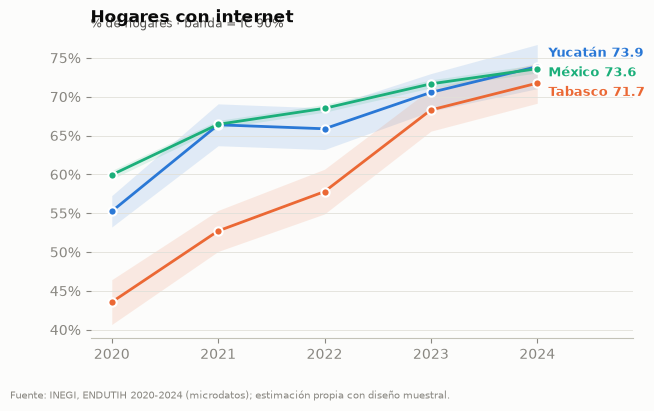

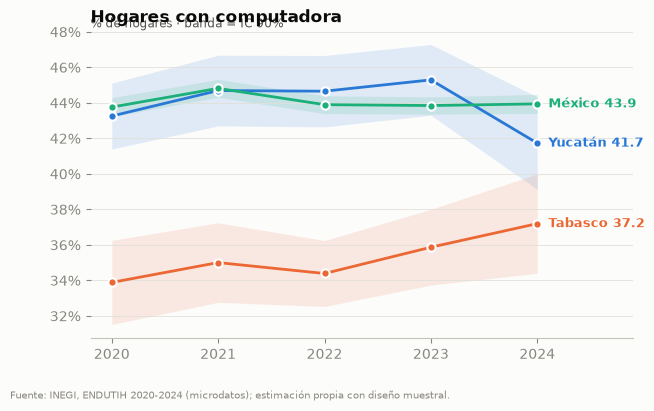

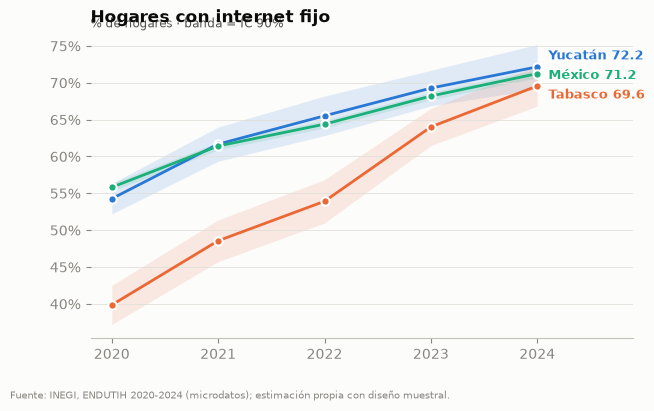

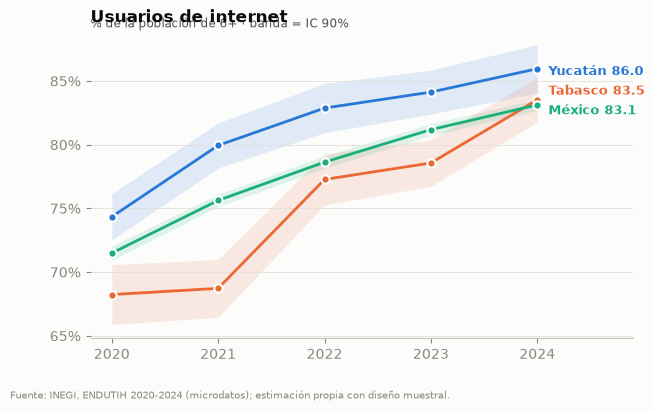

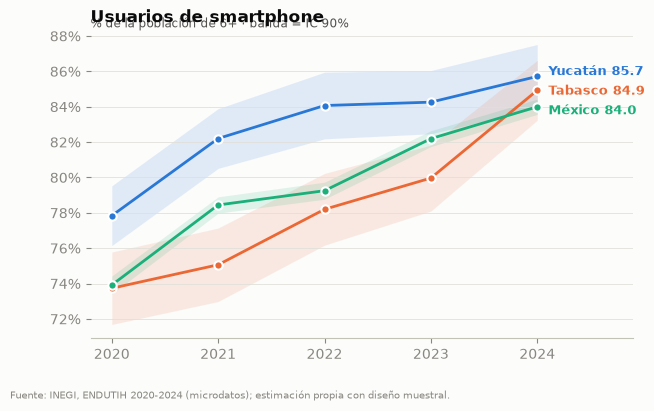

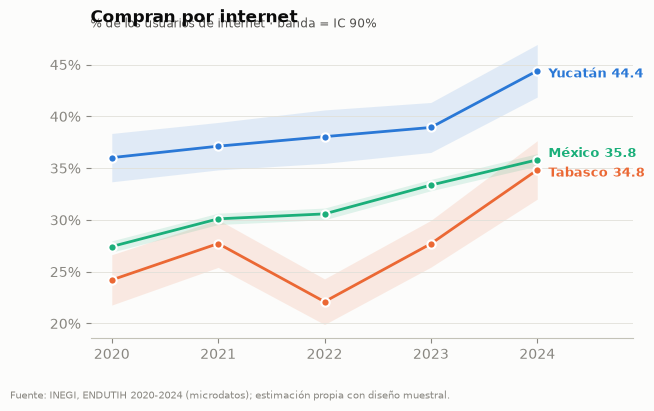

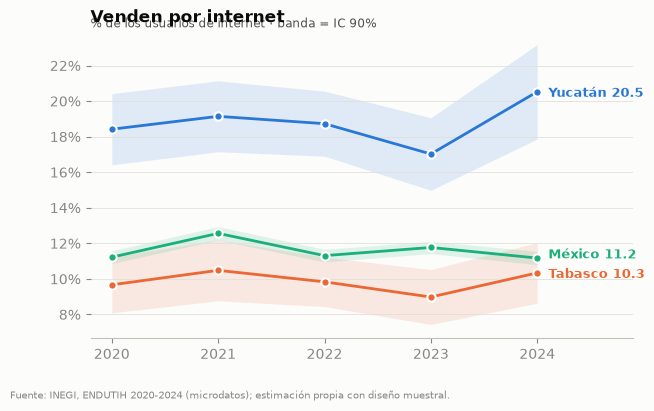

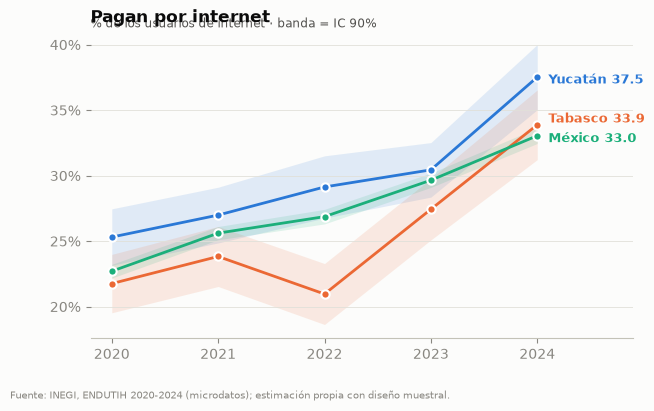

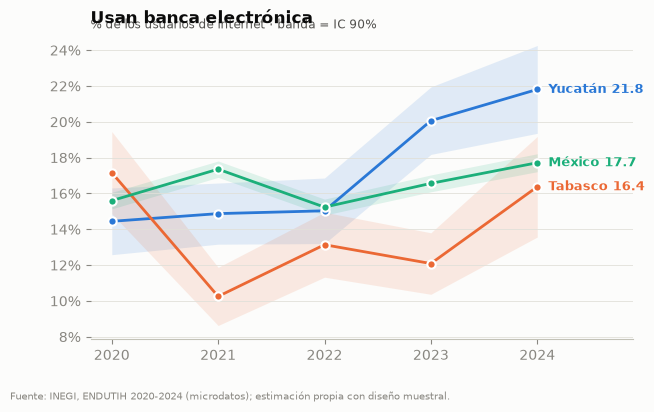

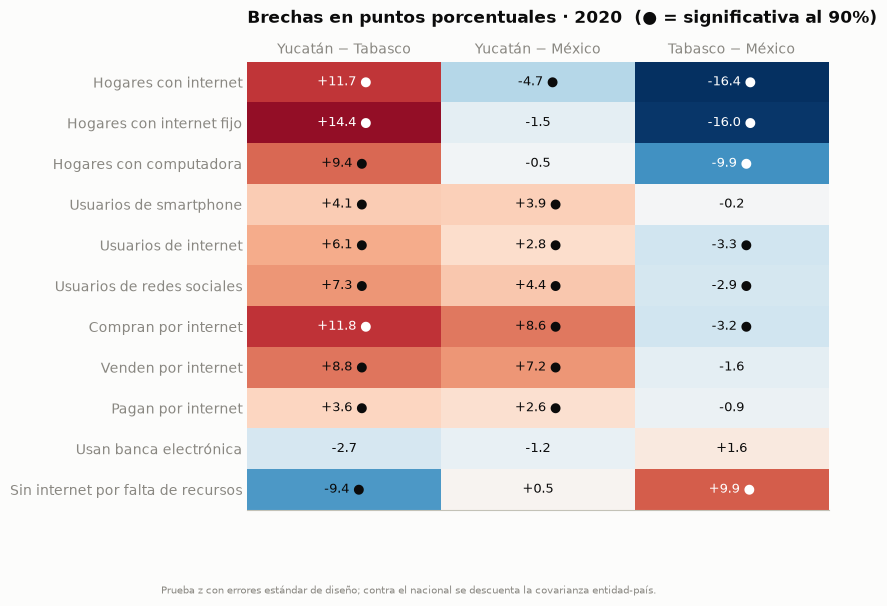

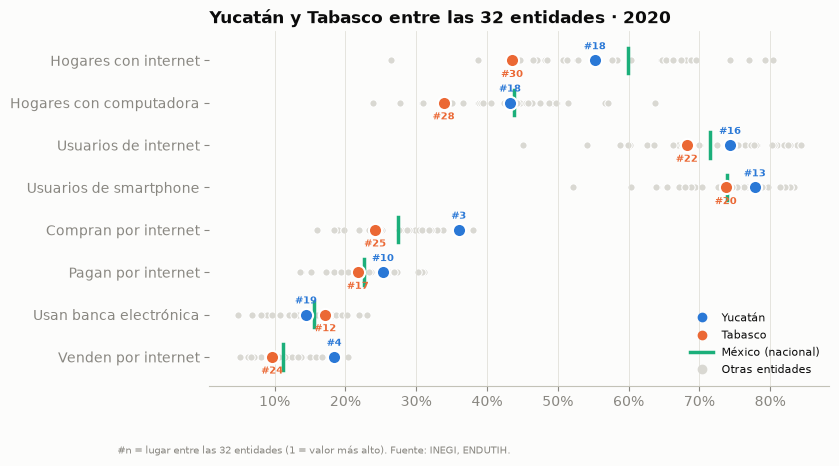

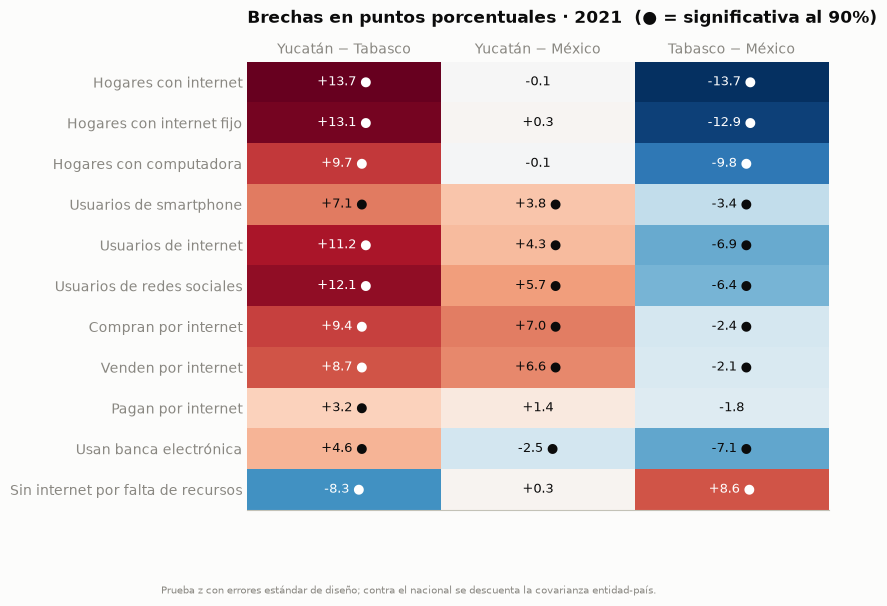

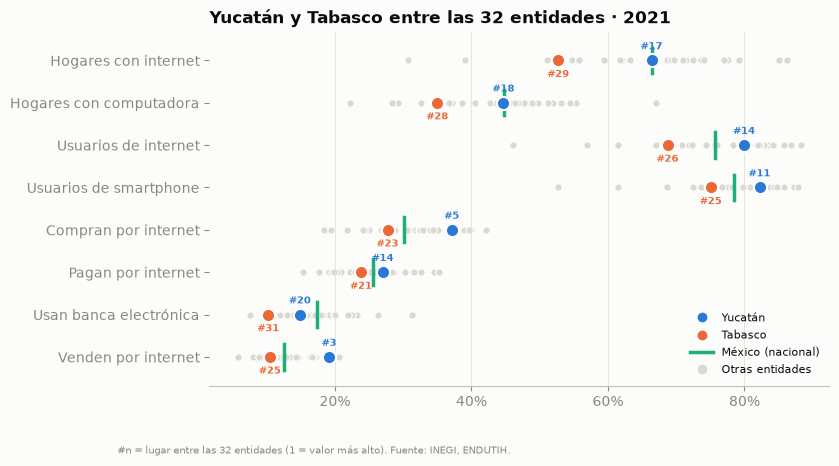

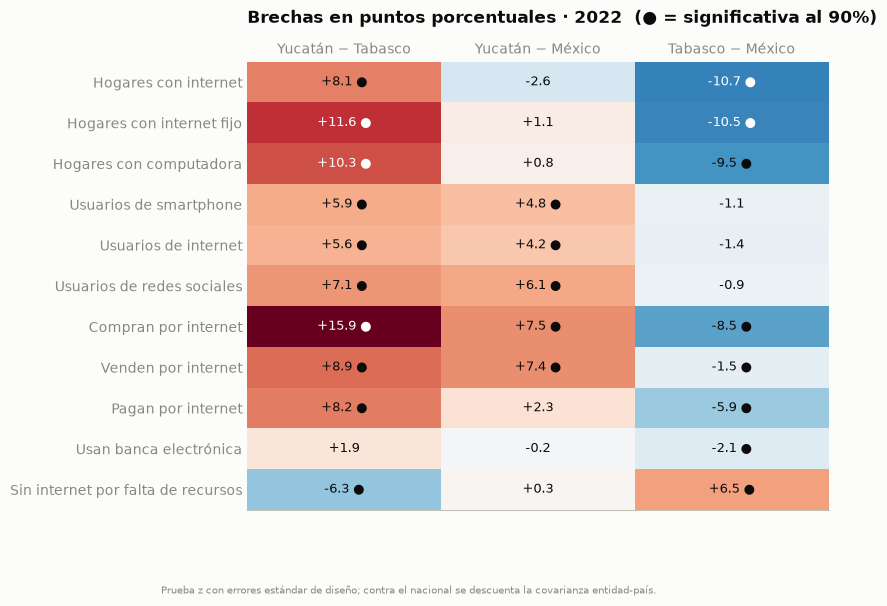

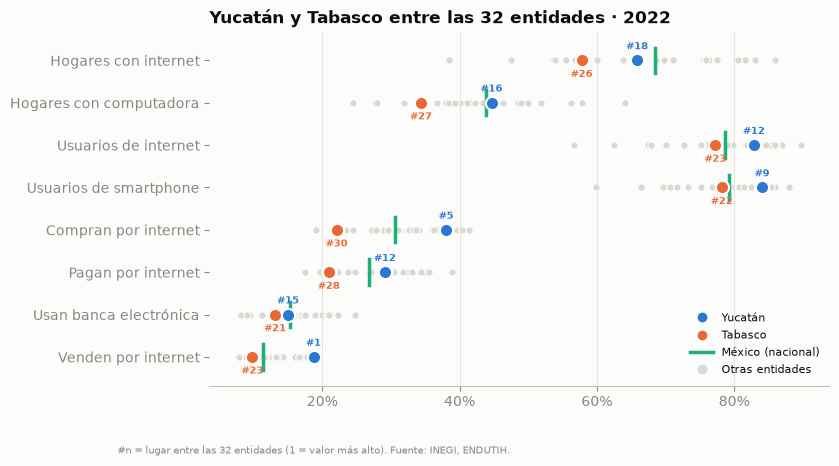

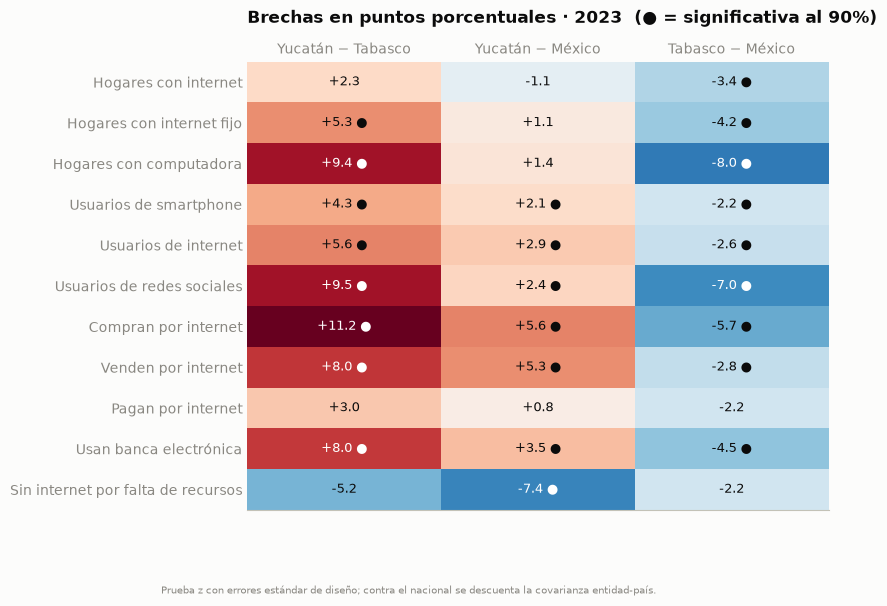

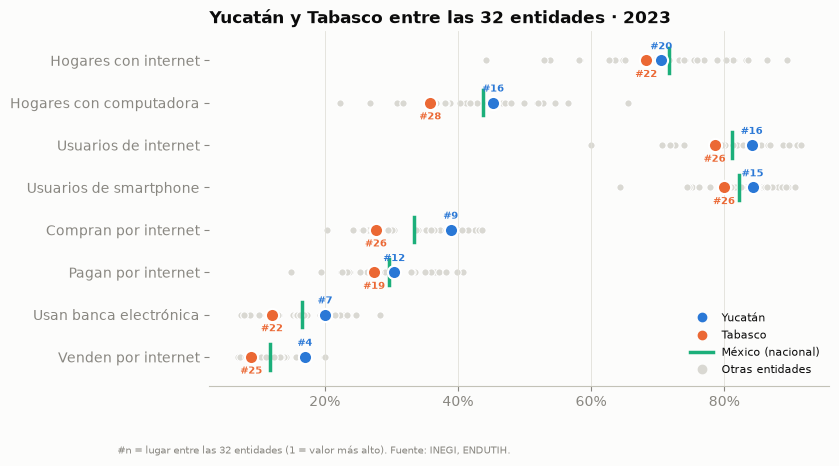

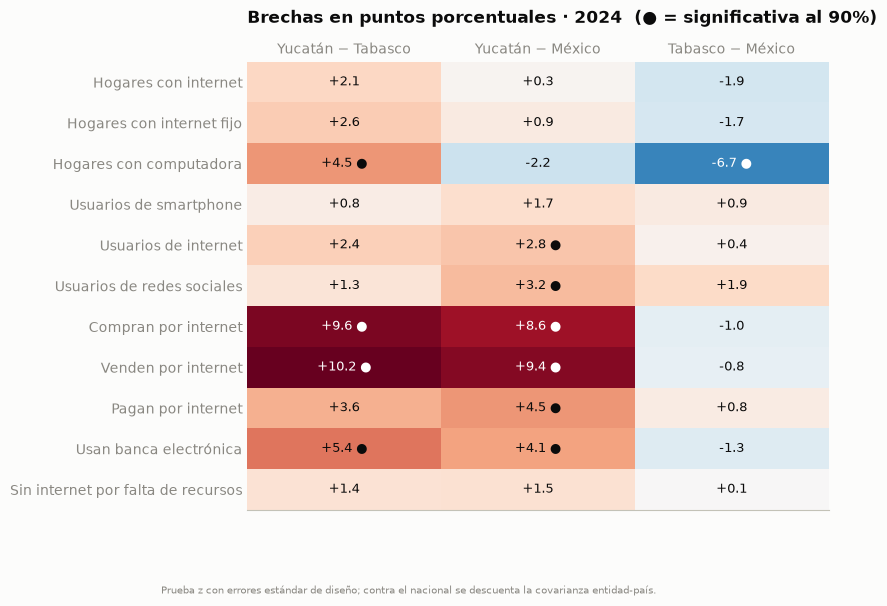

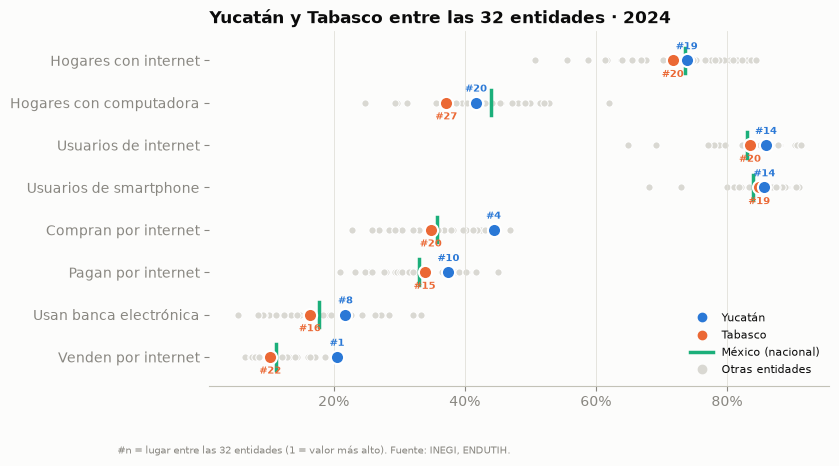

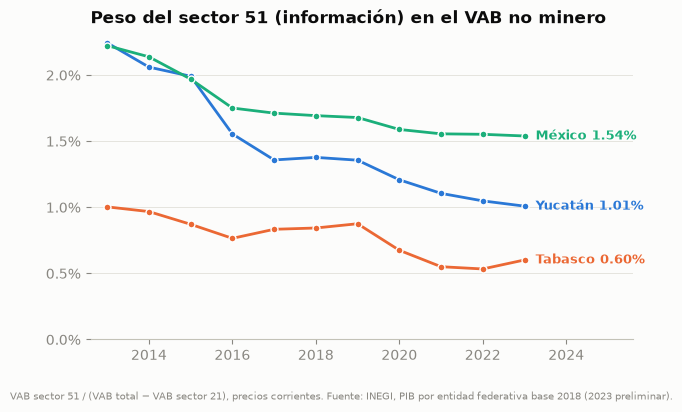

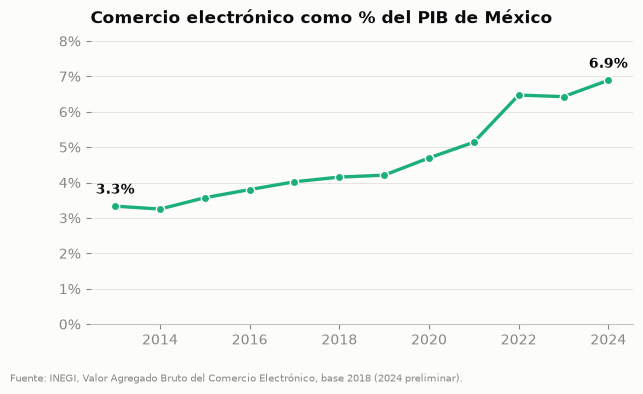

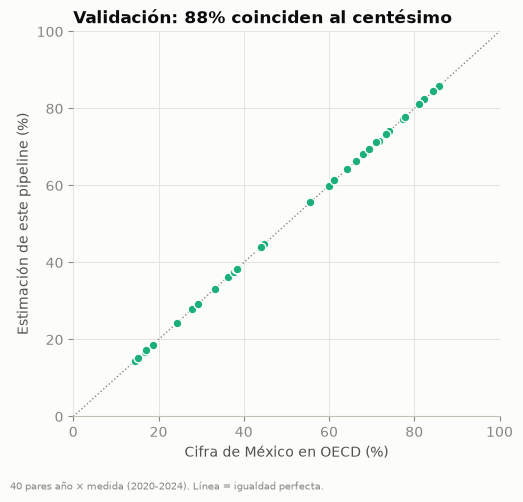

In [21]:
NAC, TAB, YUC = NACIONAL, TABASCO, YUCATAN
ORDEN = [YUC, TAB, NAC]
NOMBRES = {YUC: "Yucatán", TAB: "Tabasco", NAC: "México"}
COLOR = {YUC: "#2a78d6", TAB: "#eb6834", NAC: "#1baf7a"}
SUPERFICIE, TINTA, TINTA_2, TENUE, REJILLA = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
SERIES = ["hog_internet", "hog_computadora", "hog_internet_fija", "pob_internet", "pob_smartphone",
          "usu_compra", "usu_vende", "usu_paga", "usu_banca"]
BRECHAS = ["hog_internet", "hog_internet_fija", "hog_computadora", "pob_smartphone", "pob_internet",
           "pob_redes_sociales", "usu_compra", "usu_vende", "usu_paga", "usu_banca", "sin_internet_recursos"]

plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "font.family": "sans-serif", "font.size": 10, "text.color": TINTA, "axes.labelcolor": TINTA_2,
    "xtick.color": TENUE, "ytick.color": TENUE, "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": REJILLA, "grid.linewidth": 0.6,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
})


def guardar_fig(fig, nombre):
    plt.show()


def fuente(fig, texto):
    fig.text(0.01, -0.02, texto, fontsize=7.5, color=TENUE, ha="left", va="top")


def serie(enc, ind, nombre, unidad):
    fig, ax = plt.subplots(figsize=(7, 4))
    d = enc[(enc["id_indicador"] == ind) & enc["cve_ent"].isin(ORDEN)]
    for cve in ORDEN:
        s = d[d["cve_ent"] == cve].sort_values("anio")
        ax.fill_between(s["anio"], s["li_90"], s["ls_90"], color=COLOR[cve], alpha=0.13, linewidth=0)
        ax.plot(s["anio"], s["estimacion"], color=COLOR[cve], linewidth=2, marker="o", markersize=6,
                markeredgecolor="white", markeredgewidth=1.5, label=NOMBRES[cve])
    fin = d[d["anio"] == d["anio"].max()].sort_values("estimacion")
    rango = max(d["ls_90"].max() - d["li_90"].min(), 1)
    previo, posiciones = -np.inf, []
    for v in fin["estimacion"]:
        previo = max(v, previo + 0.07 * rango)
        posiciones.append(previo)
    ajuste = np.mean(fin["estimacion"]) - np.mean(posiciones)
    for (_, r), y in zip(fin.iterrows(), posiciones):
        ax.annotate(f"{NOMBRES[r['cve_ent']]} {r['estimacion']:.1f}", (r["anio"], y + ajuste), xytext=(8, 0),
                    textcoords="offset points", va="center", fontsize=9, color=COLOR[r["cve_ent"]], fontweight="bold")
    ax.set_xticks(sorted(d["anio"].unique()))
    ax.set_xlim(d["anio"].min() - 0.2, d["anio"].max() + 0.9)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
    ax.set_title(nombre)
    ax.text(0, 1.01, unidad + " · banda = IC 90%", transform=ax.transAxes, fontsize=8.5, color=TINTA_2)
    fuente(fig, "Fuente: INEGI, ENDUTIH 2020-2024 (microdatos); estimación propia con diseño muestral.")
    guardar_fig(fig, f"serie_{ind}.png")


def brechas_fig(br, indicadores, anio):
    pares = [(YUC, TAB, "Yucatán − Tabasco"), (YUC, NAC, "Yucatán − México"), (TAB, NAC, "Tabasco − México")]
    b = br[(br["anio"] == anio) & (br["id_indicador"].isin(BRECHAS))]
    filas = [i for i in BRECHAS if i in set(b["id_indicador"])]
    m = np.full((len(filas), 3), np.nan)
    sig = np.zeros_like(m, dtype=bool)
    for j, (a, c, _) in enumerate(pares):
        for i, ind in enumerate(filas):
            r = b[(b["id_indicador"] == ind) & (b["entidad_a"] == a) & (b["entidad_b"] == c)].iloc[0]
            m[i, j], sig[i, j] = r["diferencia_pp"], r["significativa"]
    lim = np.nanmax(np.abs(m))
    fig, ax = plt.subplots(figsize=(7.5, 0.42 * len(filas) + 1.2))
    ax.imshow(m, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
    for i in range(len(filas)):
        for j in range(3):
            ax.text(j, i, f"{m[i, j]:+.1f}" + (" ●" if sig[i, j] else ""), ha="center", va="center", fontsize=9,
                    color=TINTA if abs(m[i, j]) < 0.6 * lim else "white")
    ax.set_xticks(range(3), [p[2] for p in pares])
    ax.xaxis.tick_top()
    ax.set_yticks(range(len(filas)), [indicadores.loc[i, "nombre"] for i in filas])
    ax.grid(False)
    ax.tick_params(length=0)
    ax.set_title(f"Brechas en puntos porcentuales · {anio}  (● = significativa al 90%)", pad=28)
    fuente(fig, "Prueba z con errores estándar de diseño; contra el nacional se descuenta la covarianza entidad-país.")
    guardar_fig(fig, f"brechas_{anio}.png")


def ranking_fig(enc, rk, indicadores, anio):
    lista = ["hog_internet", "hog_computadora", "pob_internet", "pob_smartphone", "usu_compra", "usu_paga",
             "usu_banca", "usu_vende"]
    fig, ax = plt.subplots(figsize=(8, 4.6))
    for i, ind in enumerate(lista[::-1]):
        e = enc[(enc["anio"] == anio) & (enc["id_indicador"] == ind)]
        otros = e[~e["cve_ent"].isin(ORDEN)]
        ax.scatter(otros["estimacion"], [i] * len(otros), s=28, color="#d9d8d2", edgecolor="white", linewidth=0.8)
        nac = e[e["cve_ent"] == NAC]["estimacion"].iloc[0]
        ax.plot([nac, nac], [i - 0.3, i + 0.3], color=COLOR[NAC], linewidth=2.5)
        for cve in [TAB, YUC]:
            v = e[e["cve_ent"] == cve]["estimacion"].iloc[0]
            lugar = rk[(rk["anio"] == anio) & (rk["id_indicador"] == ind) & (rk["cve_ent"] == cve)]["rango"].iloc[0]
            ax.scatter([v], [i], s=90, color=COLOR[cve], edgecolor="white", linewidth=1.5, zorder=3)
            ax.annotate(f"#{lugar}", (v, i), xytext=(0, 8 if cve == YUC else -12), textcoords="offset points",
                        ha="center", fontsize=7.5, color=COLOR[cve], fontweight="bold")
    ax.set_yticks(range(len(lista)), [indicadores.loc[i, "nombre"] for i in lista[::-1]])
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
    ax.grid(axis="x", color=REJILLA)
    ax.grid(axis="y", visible=False)
    ax.set_title(f"Yucatán y Tabasco entre las 32 entidades · {anio}")
    handles = [plt.Line2D([], [], marker="o", linestyle="", color=COLOR[YUC], label="Yucatán"),
               plt.Line2D([], [], marker="o", linestyle="", color=COLOR[TAB], label="Tabasco"),
               plt.Line2D([], [], color=COLOR[NAC], linewidth=2.5, label="México (nacional)"),
               plt.Line2D([], [], marker="o", linestyle="", color="#d9d8d2", label="Otras entidades")]
    ax.legend(handles=handles, loc="lower right", frameon=False, fontsize=8)
    fuente(fig, "#n = lugar entre las 32 entidades (1 = valor más alto). Fuente: INEGI, ENDUTIH.")
    guardar_fig(fig, f"ranking_{anio}.png")


def valor_sector51(valor):
    fig, ax = plt.subplots(figsize=(7, 4))
    for cve in ORDEN:
        s = valor[(valor["cve_ent"] == cve) & (valor["anio"] >= 2013)].sort_values("anio")
        ax.plot(s["anio"], s["participacion_51_no_minero"], color=COLOR[cve], linewidth=2, marker="o", markersize=5,
                markeredgecolor="white", label=NOMBRES[cve])
        u = s.iloc[-1]
        ax.annotate(f"{NOMBRES[cve]} {u['participacion_51_no_minero']:.2f}%", (u["anio"], u["participacion_51_no_minero"]),
                    xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=COLOR[cve], fontweight="bold")
    ax.set_ylim(bottom=0)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.1f}%")
    ax.set_xlim(2012.6, 2025.6)
    ax.set_title("Peso del sector 51 (información) en el VAB no minero")
    fuente(fig, "VAB sector 51 / (VAB total − VAB sector 21), precios corrientes. Fuente: INEGI, PIB por entidad "
                "federativa base 2018 (2023 preliminar).")
    guardar_fig(fig, "valor_sector51.png")


def comercio_electronico(coel):
    fig, ax = plt.subplots(figsize=(7, 3.8))
    ax.plot(coel["anio"], coel["pct_pib"], color=COLOR[NAC], linewidth=2.4, marker="o", markersize=6, markeredgecolor="white")
    for a in [coel["anio"].min(), coel["anio"].max()]:
        v = coel.loc[coel["anio"] == a, "pct_pib"].iloc[0]
        ax.annotate(f"{v:.1f}%", (a, v), xytext=(0, 9), textcoords="offset points", ha="center", fontweight="bold")
    ax.set_ylim(0, coel["pct_pib"].max() * 1.2)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
    ax.set_title("Comercio electrónico como % del PIB de México")
    fuente(fig, "Fuente: INEGI, Valor Agregado Bruto del Comercio Electrónico, base 2018 (2024 preliminar).")
    guardar_fig(fig, "comercio_electronico.png")


def validacion_fig(val):
    fig, ax = plt.subplots(figsize=(5.5, 5))
    ax.plot([0, 100], [0, 100], color=TENUE, linewidth=1, linestyle=":")
    ax.scatter(val["valor_oecd"], val["valor_endutih"], s=40, color=COLOR[NAC], edgecolor="white", linewidth=1, zorder=3)
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.set_xlabel("Cifra de México en OECD (%)")
    ax.set_ylabel("Estimación de este pipeline (%)")
    ax.grid(axis="both", color=REJILLA)
    exactas = (val["diferencia_pp"].abs() < 0.01).mean()
    ax.set_title(f"Validación: {exactas:.0%} coinciden al centésimo")
    fuente(fig, f"{len(val)} pares año × medida (2020-2024). Línea = igualdad perfecta.")
    guardar_fig(fig, "validacion_oecd.png")


enc = leer(GOLD, "fact_encuesta_tic").query("grupo_edad == 'total'")
indicadores = leer(GOLD, "dim_indicador").set_index("id_indicador")
br = leer(GOLD, "resultado_brecha")
rk = leer(GOLD, "resultado_ranking")
valor = leer(GOLD, "valor_entidad_anio")
coel = leer(GOLD, "comercio_electronico_anio").sort_values("anio")
val = leer(GOLD, "resultado_validacion_oecd")

for ind in SERIES:
    serie(enc, ind, indicadores.loc[ind, "nombre"], indicadores.loc[ind, "unidad"])
for anio in sorted(enc["anio"].unique()):
    brechas_fig(br, indicadores, anio)
    ranking_fig(enc, rk, indicadores, anio)
valor_sector51(valor)
comercio_electronico(coel)
validacion_fig(val)

- **¿Por qué la banda de color en las series?** Es el intervalo al 90%. Si las bandas de dos estados
  se enciman mucho, a lo mejor no son tan distintos.
- **¿Por qué el punto ● en las brechas?** Para ver de un vistazo cuáles diferencias son de verdad y
  cuáles pueden ser suerte.
- **¿Por qué los otros estados en gris?** Para que se vean Yucatán y Tabasco, pero sin perder de vista
  dónde está todo el país.
- **¿Por qué estos colores?** Porque se distinguen bien aunque alguien no vea bien los colores.

## Un vistazo a gold

In [22]:
pd.DataFrame([(nombre, len(df)) for nombre, df in GOLD.items()], columns=["tabla", "filas"])

,tabla,filas
0,dim_entidad,33
1,dim_tiempo,23
2,dim_pais,45
3,fact_valor_entidad,4158
4,fact_comercio_electronico,228
5,fact_oecd_tic,3656
6,dim_indicador,23
7,fact_encuesta_tic,3160
8,valor_entidad_anio,693
9,comercio_electronico_anio,12


In [23]:
leer(GOLD, "resultado_brecha").head(10)

,anio,id_indicador,entidad_a,entidad_b,diferencia_pp,error_estandar,z,p_value,significativa
0,2020,hog_celular,31,27,0.540998,1.055744,0.512433,6.083482e-01,False
1,2020,hog_celular,31,00,0.620970,0.641885,0.967415,3.333364e-01,False
2,2020,hog_celular,27,00,0.079972,0.852442,0.093815,9.252558e-01,False
3,2020,hog_computadora,31,27,9.371391,1.829903,5.121251,3.035147e-07,True
4,2020,hog_computadora,31,00,-0.503496,1.153452,-0.436513,6.624649e-01,False
5,2020,hog_computadora,27,00,-9.874887,1.449477,-6.812724,9.576779e-12,True
6,2020,hog_internet,31,27,11.688718,2.141350,5.458574,4.799746e-08,True
7,2020,hog_internet,31,00,-4.699927,1.251474,-3.755514,1.729863e-04,True
8,2020,hog_internet,27,00,-16.388645,1.752338,-9.352444,8.564566e-21,True
9,2020,hog_internet_fija,31,27,14.417478,2.046482,7.045005,1.854552e-12,True
